# 02 - The new algorithm (EBM), model comparison and explainability

Models are trained by `python src/train.py`, figures by `src/evaluate.py` and `src/explain.py`.
This notebook loads the saved results, explains the choice of the **Explainable Boosting Machine (EBM)**,
compares it with the models from the lectures, explains it with **EBM's own explanations, SHAP, PDP/ICE and LIME**,
and runs one prediction with the pickled model.

In [1]:
import sys, json, pickle, warnings
import numpy as np, pandas as pd
warnings.filterwarnings("ignore")
sys.path.insert(0, "../src")
import config
from features import RAW_FEATURES, readable
from IPython.display import Image, display
res = pd.read_csv("../reports/model_comparison.csv")
info = json.loads(open("../models/feature_info.json").read())
print("Selected model:", info["model_name"])

Selected model: EBM (new algorithm)


## 1. The new algorithm: Explainable Boosting Machine (not covered in the lectures)

EBM (InterpretML, Microsoft Research) is a **Generalized Additive Model with pairwise interactions**:

$$g\big(P(\text{churn})\big) = b + \sum_j f_j(x_j) + \sum_{(i,j)} f_{ij}(x_i, x_j)$$

- $g$ is the logit link (as in Logistic Regression), $b$ the intercept.
- Each $f_j$ is a **shape function** learned by **cyclic gradient boosting**: thousands of rounds, each fitting a
  tiny tree on **one feature only** with a small learning rate. Outer bagging averages several such models.
- The strongest feature pairs (found with the FAST method) are added as $f_{ij}$ terms.

| Standard model | How it works | How EBM differs |
|---|---|---|
| Logistic Regression | straight-line effect per feature | free-form curve per feature + pair terms |
| Decision Tree | one tree mixing many features | thousands of one-feature trees, combined into one curve per feature |
| k-NN | compares with nearest stored customers, needs scaling | compact model, no scaling, global and local reasons |
| XGBoost / Random Forest | deep trees mixing features; need SHAP/LIME | stays additive, so the model **is** its explanation (glassbox) |

**Why it was selected:** a retention officer needs the reason behind each alert; EBM gives exact reasons while
keeping boosting-level accuracy, handles non-linear effects and works with sample weights for imbalance.

## 2. EBM tuning on a 20% validation split (PR-AUC)

In [2]:
pd.read_csv("../reports/ebm_tuning.csv")

,learning_rate,interactions,max_bins,max_leaves,min_samples_leaf,outer_bags,val_pr_auc,seconds
0,0.015,0,256,2,4,8,0.9815,101
1,0.015,10,256,2,4,8,0.9869,160
2,0.015,20,256,2,4,8,0.9895,185
3,0.015,50,256,2,4,8,0.9912,215
4,0.015,100,256,2,4,8,0.9921,262
5,0.015,200,256,2,4,8,0.9918,341
6,0.030,100,256,3,4,8,0.9926,120


More pairwise interactions help up to about 100 pairs; 200 pairs gives no further gain. The selected setting is
100 pairs, learning rate 0.015, max leaves 2, 8 outer bags. Churners get sample weight ≈ 3.3.
Benchmark models were tuned with RandomizedSearchCV (`reports/hyperparameters.csv`).

## 3. Test-set comparison (13,000 customers, used once)

In [3]:
res[["model", "val_pr_auc", "test_accuracy", "test_precision", "test_recall", "test_f1",
     "test_roc_auc", "test_pr_auc", "train_f1", "train_time_s"]].round(4)

,model,val_pr_auc,test_accuracy,test_precision,test_recall,test_f1,test_roc_auc,test_pr_auc,train_f1,train_time_s
0,EBM (new algorithm),0.9930,0.9809,0.9455,0.9728,0.9589,0.9977,0.9930,0.9828,346.6592
1,Majority baseline,0.2311,0.7710,0.0000,0.0000,0.0000,0.5000,0.2290,0.0000,0.7346
2,Logistic Regression,0.9332,0.9167,0.7628,0.9234,0.8354,0.9749,0.9291,0.8426,2.6393
3,Decision Tree,0.7683,0.8603,0.6613,0.7995,0.7238,0.9118,0.7801,0.7348,3.9887
4,Random Forest,0.9370,0.9328,0.8429,0.8687,0.8556,0.9771,0.9381,0.9787,39.3282
5,AdaBoost,0.9857,0.9732,0.9494,0.9325,0.9409,0.9954,0.9864,0.9511,346.2330
6,XGBoost,0.9925,0.9800,0.9435,0.9708,0.9570,0.9976,0.9927,0.9894,5.8985
7,LightGBM,0.9931,0.9825,0.9541,0.9704,0.9622,0.9979,0.9937,0.9954,7.2871
8,CatBoost,0.9930,0.9813,0.9404,0.9805,0.9600,0.9980,0.9941,0.9737,15.7863
9,Soft Voting (XGB + LGBM + CatBoost),0.9935,0.9820,0.9489,0.9738,0.9612,0.9980,0.9940,0.9896,28.4482


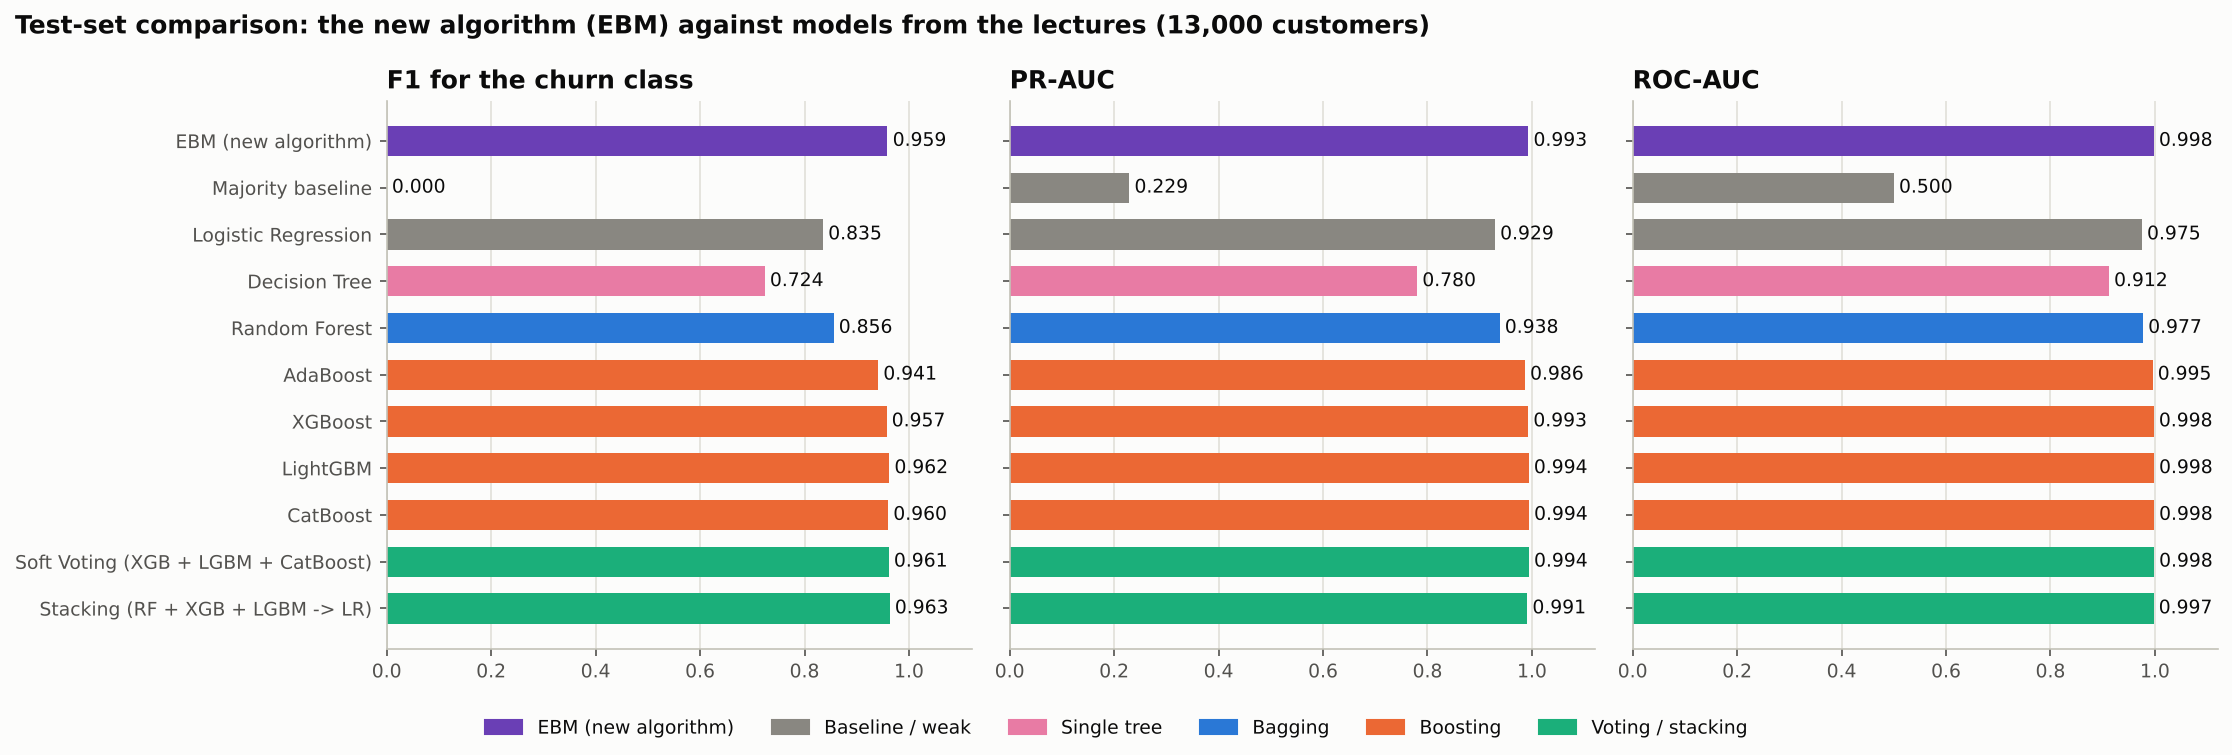

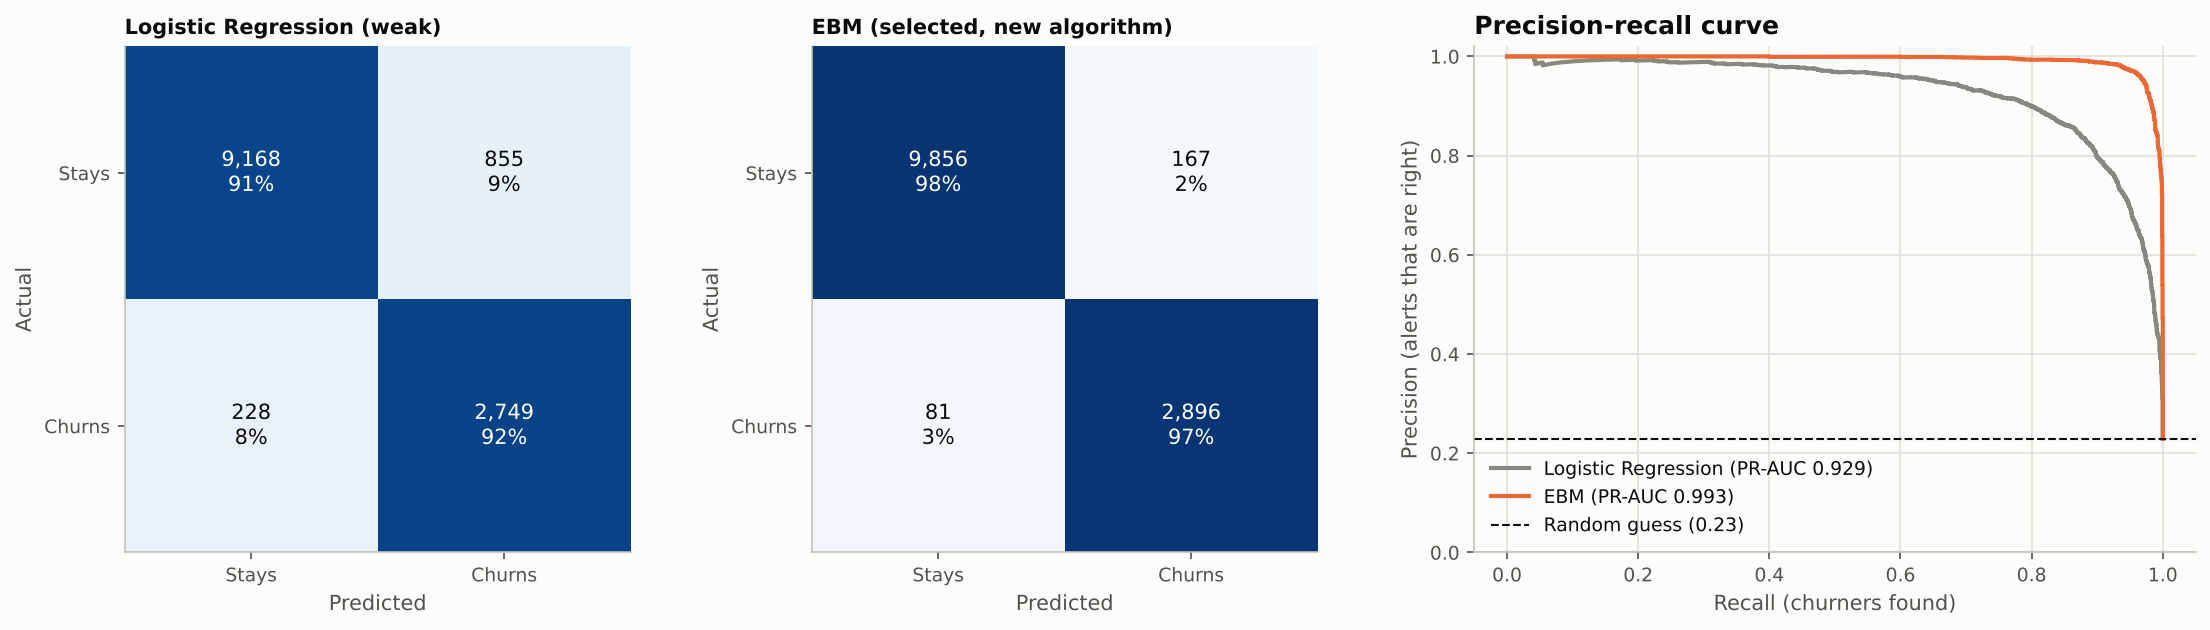

{'Logistic Regression': {'tn': 9168, 'fp': 855, 'fn': 228, 'tp': 2749}, 'EBM (new algorithm)': {'tn': 9856, 'fp': 167, 'fn': 81, 'tp': 2896}}


In [4]:
display(Image("../reports/figures/model_comparison.png"))
display(Image("../reports/figures/weak_vs_best.png"))
print(json.loads(open("../reports/confusion_matrices.json").read()))

- The majority baseline is 77% accurate but finds no churners, so accuracy is not used to compare.
- EBM matches the strongest black-box models (XGBoost, LightGBM, CatBoost, voting, stacking are all within about 0.005 F1).
- Against the weak Logistic Regression, EBM cuts false alarms from 855 to 167 and missed churners from 228 to 81.

## 4. Explainability

### 4.1 EBM global importance and importance by usage type

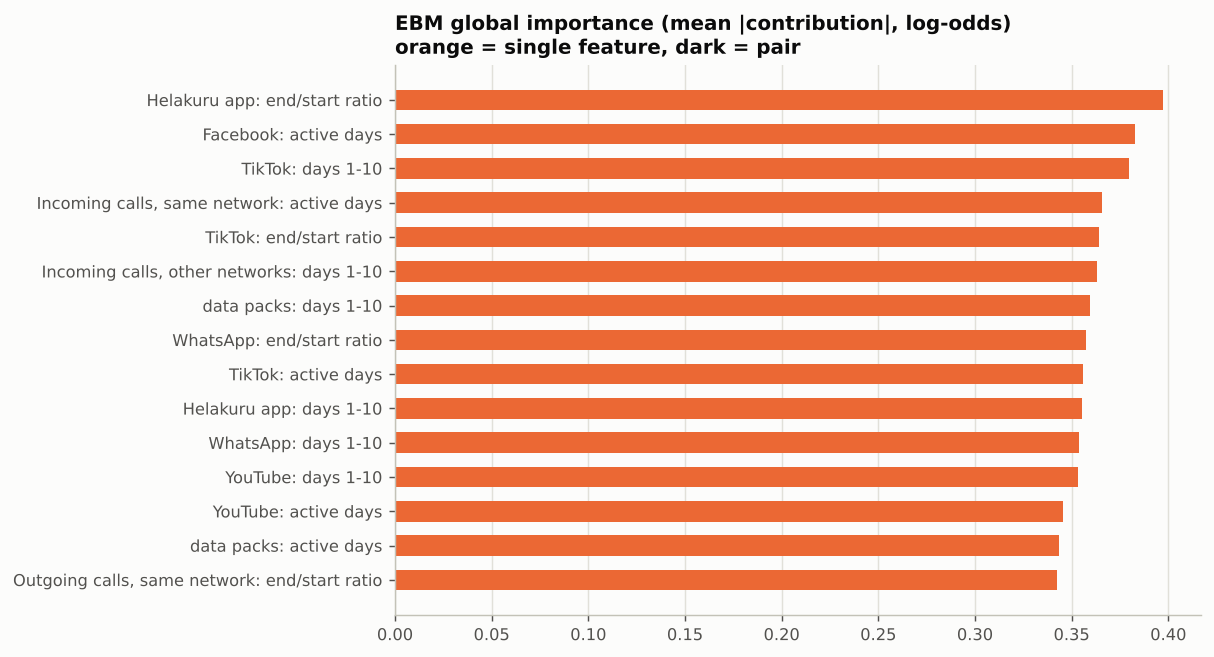

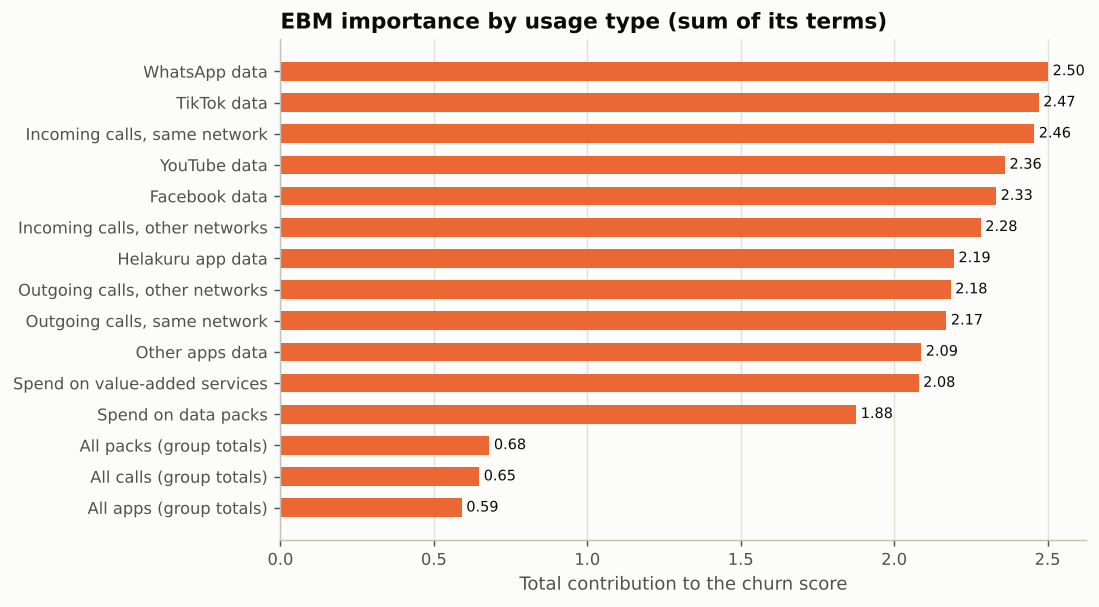

In [5]:
display(Image("../reports/figures/ebm_importance.png"))
display(Image("../reports/figures/ebm_by_usage_type.png"))

### 4.2 EBM shape functions (each curve is the feature's exact effect)

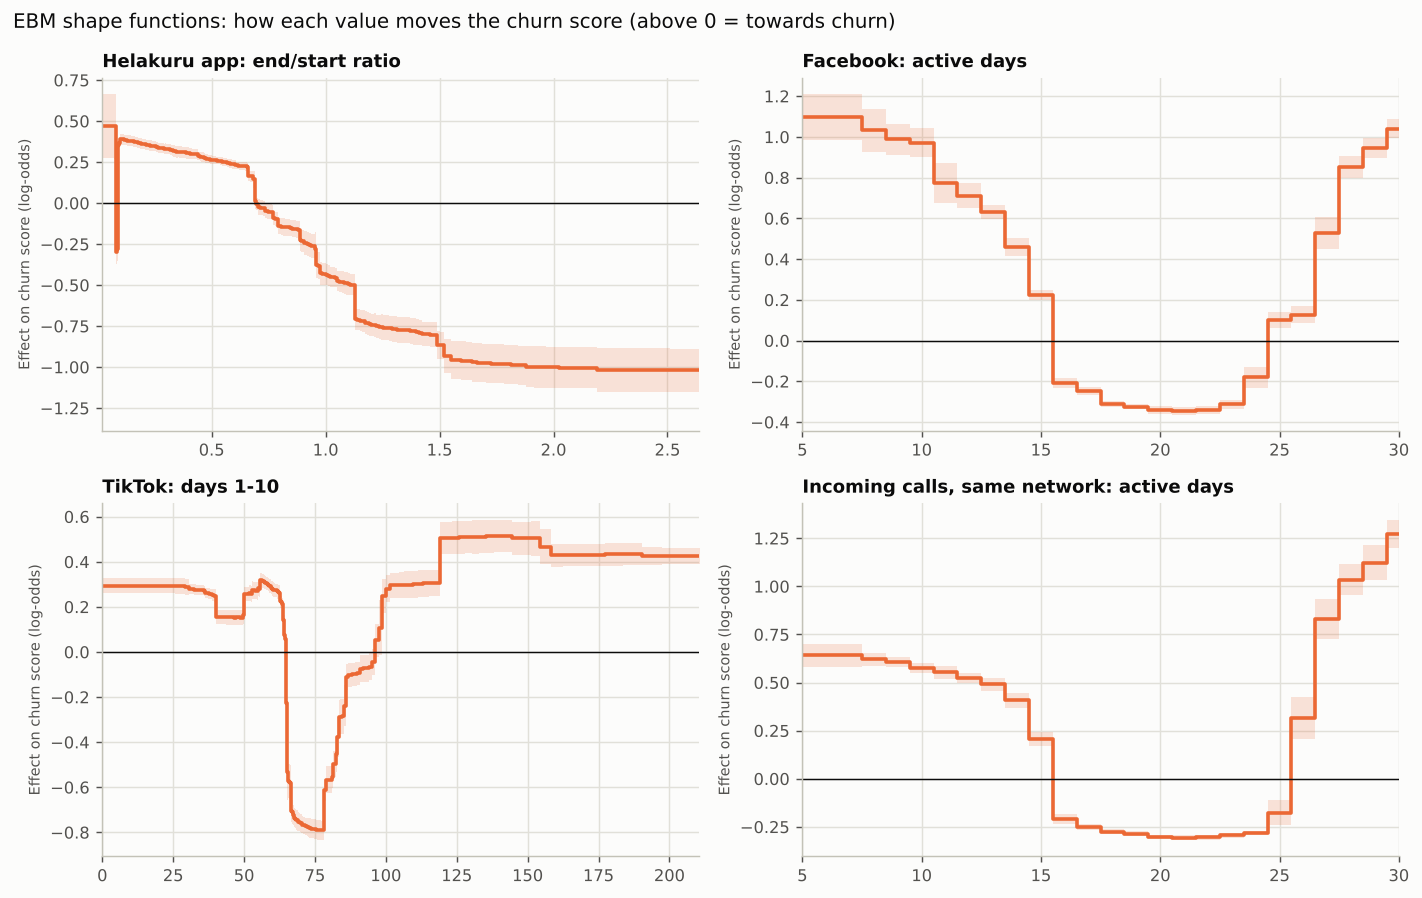

In [6]:
display(Image("../reports/figures/ebm_shape_functions.png"))

### 4.3 SHAP (from the additive terms) and Partial Dependence / ICE

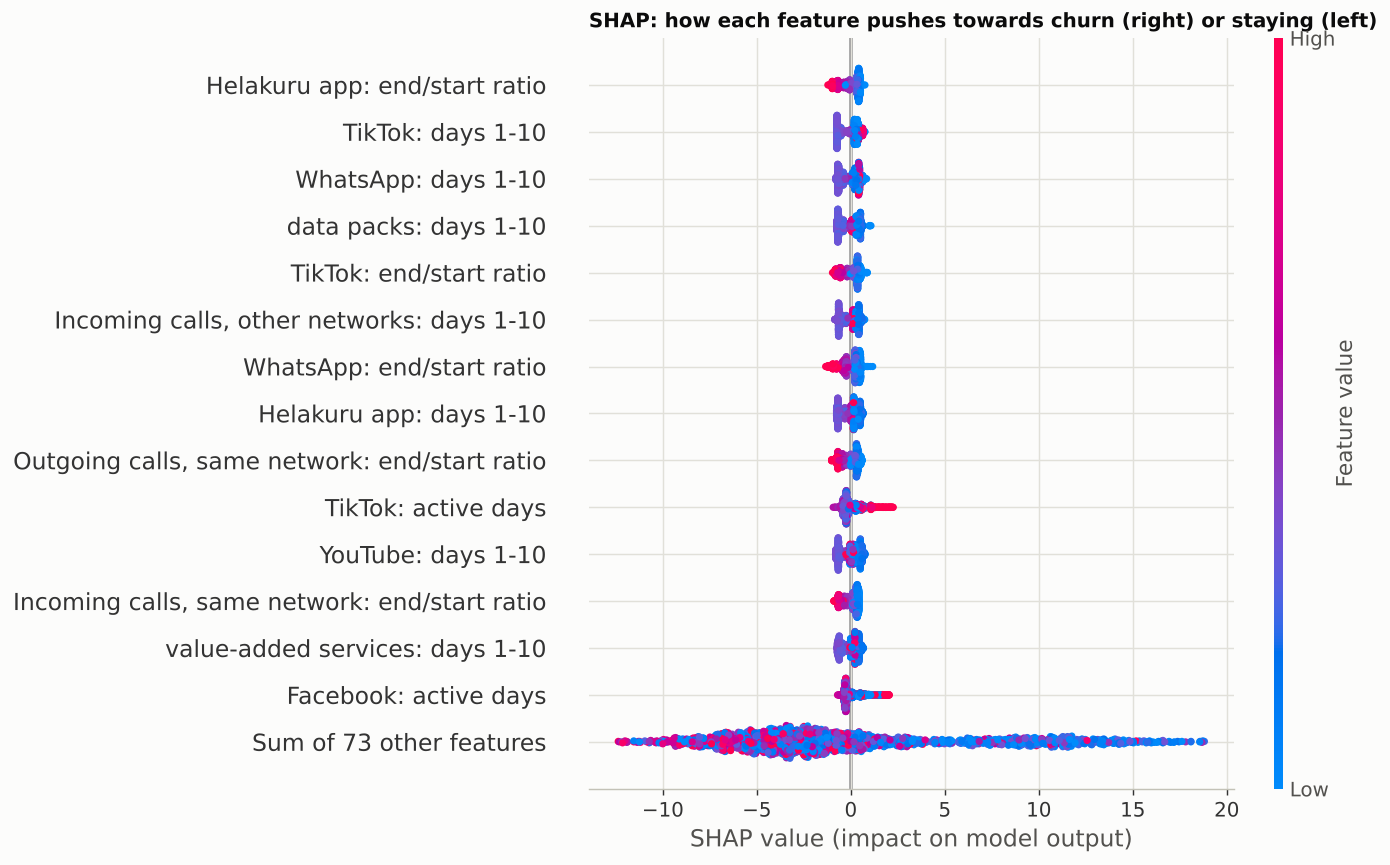

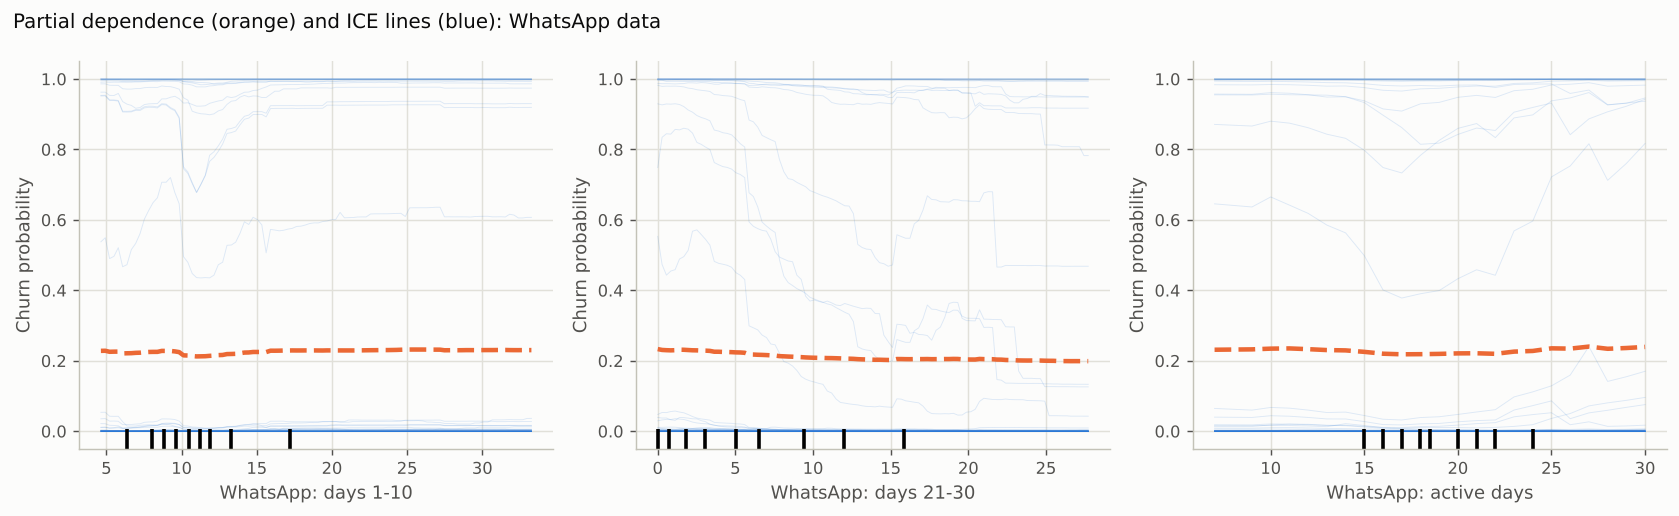

In [7]:
display(Image("../reports/figures/shap_beeswarm.png"))
display(Image("../reports/figures/pdp_top_usage_type.png"))

### 4.4 One customer: EBM contributions and LIME

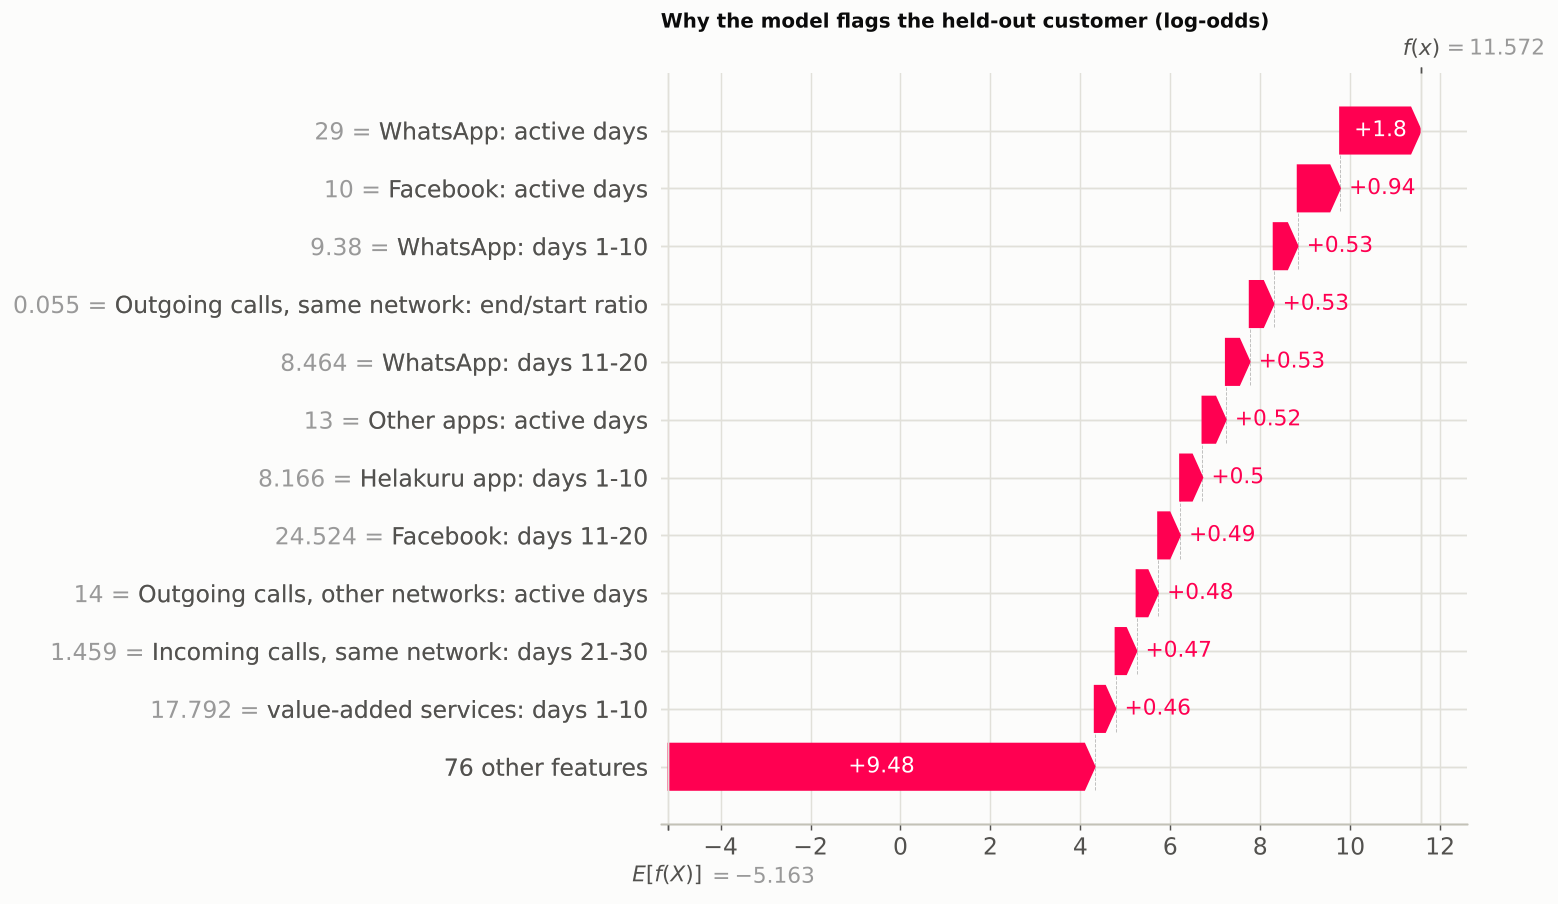

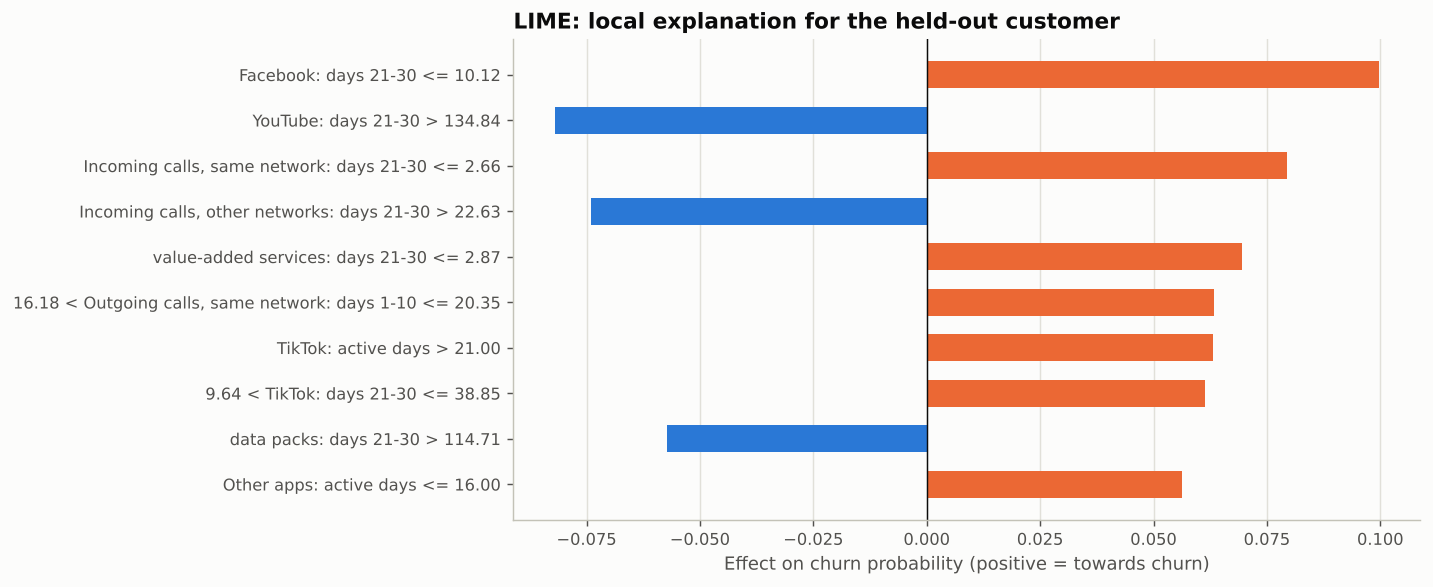

{'holdout_churn_probability': 1.0,
 'holdout_true_label': 1,
 'n_terms': 187,
 'n_pairs': 100}

In [8]:
display(Image("../reports/figures/shap_waterfall_holdout.png"))
display(Image("../reports/figures/lime_holdout.png"))
summary = json.loads(open("../reports/explainability_summary.json").read())
{k: summary[k] for k in ("holdout_churn_probability", "holdout_true_label", "n_terms", "n_pairs")}

**What the model learned and domain knowledge**

- Churn shows up as **falling and irregular use across all services**; importance is spread over the 12 usage types
  (WhatsApp, TikTok and same-network incoming calls are highest).
- The Helakuru end/start ratio curve is the clearest: falling use (ratio below about 0.7) pushes towards churn,
  rising use (ratio above 1) strongly towards staying. This matches telecom experience.
- Few active days (about 15 or fewer of 30) push towards churn, as expected for a customer who is leaving.
- Some curves do **not** match intuition (for example near-daily activity also raising risk, and a sharp dip for
  TikTok use of about 65-80 MB per day). These look like artefacts of the anonymised, rescaled data and are
  discussed in the report.

## 5. Inference with the pickled model on the held-out customer

In [9]:
model = pickle.load(open("../models/model.pkl", "rb"))       # full pipeline: features + EBM
holdout = pd.read_csv("../data/processed/inference_sample.csv")
prob = model.predict_proba(holdout[RAW_FEATURES])[0, 1]
print(f"Churn probability: {prob:.4f} | predicted: {'Churns' if prob >= 0.5 else 'Stays'} "
      f"| actual: {info['class_labels'][str(int(holdout[config.TARGET].iloc[0]))]}")
ebm = model[-1]
contrib = pd.Series(ebm.eval_terms(model[:-1].transform(holdout[RAW_FEATURES]))[0],
                    index=[" x ".join(readable(p.strip()) for p in n.split(" & ")) for n in ebm.term_names_])
contrib.reindex(contrib.abs().sort_values(ascending=False).index).head(10).round(3).to_frame("contribution (log-odds)")

Churn probability: 1.0000 | predicted: Churns | actual: Churns


,contribution (log-odds)
WhatsApp: days 11-20 x WhatsApp: active days,1.006
Facebook: active days,0.972
WhatsApp: active days,0.947
Other apps: active days,0.466
Helakuru app: days 1-10,0.441
"Outgoing calls, same network: end/start ratio",0.437
"Outgoing calls, same network: days 1-10",0.424
"Incoming calls, same network: active days",0.407
value-added services: days 1-10,0.392
Helakuru app: active days,0.389
